# Markov-switching AR(1): does mean reversion depend on a hidden market regime?
### Parametric check on the "conditional edge" result from meta-labeling

**Idea in one line.** Returns may follow different rules in different market states. We assume there are two hidden states, let the data decide when each one is active, and estimate a separate AR(1) inside each:

$$ r_t = \mu_{s_t} + \phi_{s_t}\, r_{t-1} + \sigma_{s_t}\,\varepsilon_t, \qquad s_t \in \{\text{calm},\ \text{turbulent}\}, \qquad P(s_t = j \mid s_{t-1} = i) = p_{ij} $$

* $\phi < 0$ means mean reversion: a down day tends to be followed by a partial bounce.
* **Main question:** is $\phi_\text{calm} = \phi_\text{turb}$? If not, mean reversion is *conditional* on the regime.
* **Link to our strategy:** we then check which hidden state the strategy is in when it actually trades (252-day trend filter combined with the 20-day ±2 SD Bollinger trigger).
* **Is it an edge?** Out of sample, we test whether the regime-switching forecast beats a plain AR(1).

| Section | What it does |
|---|---|
| 1 | Load the two TRI panels and build daily returns plus the strategy's conditions (all measured at t-1) |
| 2 | Helper functions: Newey-West OLS, Benjamini-Hochberg adjustment |
| 3 | Baseline: one AR(1) for all days |
| 4 | The Markov-switching model: Hamilton filter, Kim smoother, EM estimation |
| 5 | Results: $\phi$ by state, Wald test, persistence, volatility |
| 6 | Where does the strategy trade? Hidden state vs trend filter and entry setups |
| 7 | Cross-check against `statsmodels` (optional) |
| 8 | Out-of-sample test vs the historical mean and vs the plain AR(1) |
| 9 | Summary across the 24 ETFs and conclusion |

Requires `numpy pandas scipy matplotlib`; `statsmodels` is optional. Full run time is about 10 minutes (Sections 5 and 8 fit 48 models).

## 0. Setup and configuration

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# ---------------- paths ----------------
DATA_DIR = Path(".")                       # folder holding the two CSVs
FILES = {
    "Cross-asset (14)": "tri_full_panel_14assets.csv",
    "Sectors (10)":     "tri_full_panel_10sectors.csv",
}
OUT_DIR = Path("outputs_ms_ar")            # separate folder: earlier outputs are not overwritten
OUT_DIR.mkdir(exist_ok=True)

# ---------------- strategy parameters (match the six-condition report) ----------------
TREND_WIN = 252     # trend filter: price vs 252-day moving average
BB_WIN    = 20      # Bollinger window
BB_K      = 2.0     # Bollinger band width (SDs)
LONG_ONLY = False   # True -> the strategy's entry setup is only "uptrend & below lower band"

# ---------------- model settings ----------------
FREQ       = "D"    # "D" daily (strategy frequency) or "W" weekly non-overlapping returns
RET_SCALE  = 100.0  # returns in % (better numerical conditioning)
MS_STARTS  = 3      # random EM restarts (+1 deterministic start); raise for more robustness
MS_MAXIT   = 300
TRAIN_FRAC = 0.70   # out-of-sample split
ALPHA      = 0.05
SEED       = 42
rng = np.random.default_rng(SEED)

# chart styling
C_CALM, C_TURB = "#2a78d6", "#eb6834"
C_INK, C_MUTED, C_GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "xtick.color": C_MUTED,
    "ytick.color": C_MUTED, "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9, "legend.frameon": False,
})

## 1. Data

Both CSVs hold **total-return indices** (dividends reinvested, rebased to 1.0). Each ETF is analysed on its own available history (XLRE starts in 2015).

For every day $t$ we build:
* `y` = $r_t$, the log return in %; `x` = $r_{t-1}$
* `trend_up` = 1 if the price at $t-1$ is above its 252-day moving average (the strategy's trend filter)
* `z` = Bollinger z-score at $t-1$: $(P - \text{MA}_{20})/\text{SD}_{20}$
* `long_setup` = trend up **and** $z < -2$ (buy the dip in an uptrend)
* `short_setup` = trend down **and** $z > +2$ (sell the rally in a downtrend)

Everything on the right-hand side is known at $t-1$, so there is no look-ahead.

In [2]:
def load_tri(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, parse_dates=["dlycaldt"]).set_index("dlycaldt").sort_index()
    df.index.name = "date"
    return df.astype(float)

panels = {name: load_tri(DATA_DIR / f) for name, f in FILES.items()}
tri = pd.concat(panels.values(), axis=1).sort_index()
UNIVERSE = {t: name for name, df in panels.items() for t in df.columns}
TICKERS = list(UNIVERSE)

def build_asset_frame(p: pd.Series, freq: str = FREQ) -> pd.DataFrame:
    p = p.dropna()
    logp = np.log(p)
    trend_gap = logp - np.log(p.rolling(TREND_WIN).mean())
    z = (p - p.rolling(BB_WIN).mean()) / p.rolling(BB_WIN).std()
    state = pd.DataFrame({"logp": logp, "trend_gap": trend_gap, "z": z})
    if freq == "W":
        state = state.resample("W-FRI").last().dropna(how="all")
    r = state["logp"].diff() * RET_SCALE
    out = pd.DataFrame({"y": r, "x": r.shift(1),
                        "trend_gap": state["trend_gap"].shift(1),
                        "z": state["z"].shift(1)}).dropna()
    out["trend_up"] = (out["trend_gap"] > 0).astype(int)
    out["long_setup"] = ((out["trend_gap"] > 0) & (out["z"] < -BB_K)).astype(int)
    out["short_setup"] = (0 if LONG_ONLY else
                          ((out["trend_gap"] < 0) & (out["z"] > BB_K))).astype(int)
    return out

frames = {t: build_asset_frame(tri[t]) for t in TICKERS}
pd.DataFrame({t: {"universe": UNIVERSE[t], "first": f.index[0].date(), "n": len(f),
                  "% trend up": 100 * f["trend_up"].mean(),
                  "% long setup": 100 * f["long_setup"].mean(),
                  "% short setup": 100 * f["short_setup"].mean()}
              for t, f in frames.items()}).T

,universe,first,n,% trend up,% long setup,% short setup
DBC,Cross-asset (14),2007-02-06,4757,52.3649,1.4715,1.3874
EEM,Cross-asset (14),2004-04-13,5466,67.0143,1.7746,0.8233
EFA,Cross-asset (14),2002-08-23,5877,70.0017,2.5693,0.6126
GLD,Cross-asset (14),2005-11-17,5061,68.9587,1.7585,0.9682
HYG,Cross-asset (14),2008-04-10,4461,79.1302,2.9590,0.4932
IEF,Cross-asset (14),2003-07-28,5645,69.3357,2.1435,0.7795
IWM,Cross-asset (14),2001-05-29,6186,68.8328,2.3440,0.6628
LQD,Cross-asset (14),2003-07-28,5645,74.2250,2.4978,0.7795
QQQ,Cross-asset (14),2000-03-08,6494,74.5457,2.4484,0.6006
SHY,Cross-asset (14),2003-07-28,5645,86.5013,2.3384,0.3012


## 2. Helpers

* `ols_nw`: OLS with **Newey-West** standard errors. Daily returns have volatility clustering, so ordinary SEs are too small.
* `bh_adjust`: **Benjamini-Hochberg** adjustment. With 24 ETFs, about one false positive is expected at 5% even if nothing is going on.

In [3]:
def ols_nw(y, X, lags=None):
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    L = int(np.floor(4 * (n / 100) ** (2 / 9))) if lags is None else lags
    Xe = X * e[:, None]
    S = Xe.T @ Xe
    for l in range(1, L + 1):
        G = Xe[l:].T @ Xe[:-l]
        S += (1 - l / (L + 1)) * (G + G.T)
    V = XtX_inv @ S @ XtX_inv * n / (n - k)
    se = np.sqrt(np.diag(V))
    return {"b": b, "se": se, "t": b / se, "p": 2 * stats.norm.sf(np.abs(b / se)), "n": n}

def bh_adjust(p: pd.Series) -> pd.Series:
    s = p.dropna(); m = len(s)
    order = s.sort_values()
    adj = (order * m / np.arange(1, m + 1))[::-1].cummin()[::-1].clip(upper=1)
    return adj.reindex(p.index)

def dot_whisker(ax, est, cols, labels, colors, title):
    offs = np.linspace(-0.18, 0.18, len(cols)) if len(cols) > 1 else [0.0]
    ypos = np.arange(len(est))[::-1]
    for c, lab, col, o in zip(cols, labels, colors, offs):
        ax.errorbar(est[c], ypos + o, xerr=1.96 * est[f"se_{c}"], fmt="o", ms=4, color=col,
                    ecolor=col, elinewidth=1.4, capsize=0, label=lab)
    ax.axvline(0, color=C_MUTED, lw=0.8)
    ax.set_yticks(ypos, est.index)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)

## 3. Baseline: a single AR(1) for all days

$r_t = c + \phi\, r_{t-1} + \varepsilon_t$. The Markov-switching model has to improve on this.

In [4]:
lin_ar = pd.DataFrame({
    t: (lambda r: {"universe": UNIVERSE[t], "phi": r["b"][1], "se_phi": r["se"][1], "p_phi": r["p"][1]})(
        ols_nw(f["y"].values, np.column_stack([np.ones(len(f)), f["x"].values])))
    for t, f in frames.items()}).T
lin_ar[["phi", "se_phi", "p_phi"]] = lin_ar[["phi", "se_phi", "p_phi"]].astype(float)
lin_ar["p_phi_BH"] = bh_adjust(lin_ar["p_phi"])
lin_ar

,universe,phi,se_phi,p_phi,p_phi_BH
DBC,Cross-asset (14),0.0004,0.0153,0.9786,0.9786
EEM,Cross-asset (14),-0.1117,0.0232,0.0000,0.0000
EFA,Cross-asset (14),-0.1049,0.0236,0.0000,0.0001
GLD,Cross-asset (14),-0.0145,0.0196,0.4588,0.5506
HYG,Cross-asset (14),0.0021,0.0354,0.9517,0.9786
IEF,Cross-asset (14),-0.0303,0.0150,0.0436,0.0805
IWM,Cross-asset (14),-0.0660,0.0220,0.0027,0.0094
LQD,Cross-asset (14),0.0027,0.0641,0.9665,0.9786
QQQ,Cross-asset (14),-0.0528,0.0213,0.0132,0.0289
SHY,Cross-asset (14),-0.0729,0.0206,0.0004,0.0024


## 4. The Markov-switching model

**How the hidden state is inferred.** Each day we hold a probability for each state. We move it forward with the transition matrix $P$ (yesterday's state predicts today's), then update it with how well each state's AR(1) explains today's return. A turbulent state with $\sigma$ about 2.5 times larger "explains" a big move much better, so big moves push the probability toward turbulent.

* **Hamilton filter:** $P(s_t \mid \text{data up to } t)$. This is what a trader could know in real time, and it is used for the out-of-sample forecasts.
* **Kim smoother:** $P(s_t \mid \text{all data})$, the best hindsight estimate, used for in-sample description.
* **EM algorithm** (estimation): alternate between
  * (E) computing the state probabilities with the current parameters, and
  * (M) re-estimating each state's $\mu, \phi, \sigma$ by *weighted* least squares, weighting each day by its probability of being in that state, plus updating $P$ from the expected number of switches.

  Each round raises the likelihood. We stop when it no longer improves and keep the best of several random starting points.
* **Labelling:** the state with the lower $\sigma$ is called **calm** (state 0), the other **turbulent** (state 1).
* **Standard errors:** from the numerical Hessian of the log-likelihood, giving the Wald test $\phi_\text{calm} = \phi_\text{turb}$.

In [5]:
SQ2PI = np.sqrt(2 * np.pi)

def _dens(y, x, mu, phi, sig):
    e = (y[:, None] - mu[None, :] - phi[None, :] * x[:, None]) / sig[None, :]
    return np.exp(-0.5 * e ** 2) / (sig[None, :] * SQ2PI)

def hamilton_filter(y, x, mu, phi, sig, P, smooth=False):
    # Returns log-lik, filtered P(s_t|t), predicted P(s_t|t-1), smoothed P(s_t|T).
    n = len(y)
    eta = _dens(y, x, mu, phi, sig)
    e0, e1 = eta[:, 0].tolist(), eta[:, 1].tolist()
    p00, p01, p10, p11 = P[0, 0], P[0, 1], P[1, 0], P[1, 1]
    f0 = (1 - p11) / (2 - p00 - p11); f1 = 1 - f0          # start at the long-run probabilities
    filt = np.empty((n, 2)); pred = np.empty((n, 2)); ll = 0.0
    for t in range(n):
        a0 = f0 * p00 + f1 * p10                            # predict: P(s_t | t-1)
        a1 = f0 * p01 + f1 * p11
        j0, j1 = a0 * e0[t], a1 * e1[t]                     # update with today's return
        lik = j0 + j1
        if lik <= 0 or not np.isfinite(lik):
            return -np.inf, None, None, None
        ll += np.log(lik)
        f0, f1 = j0 / lik, j1 / lik
        pred[t] = a0, a1
        filt[t] = f0, f1
    if not smooth:
        return ll, filt, pred, None
    sm = np.empty((n, 2)); sm[-1] = filt[-1]; s0, s1 = sm[-1]
    F, Pr = filt.tolist(), pred.tolist()
    for t in range(n - 2, -1, -1):                          # Kim backward pass
        r0, r1 = s0 / Pr[t + 1][0], s1 / Pr[t + 1][1]
        s0 = F[t][0] * (p00 * r0 + p01 * r1)
        s1 = F[t][1] * (p10 * r0 + p11 * r1)
        tot = s0 + s1; s0, s1 = s0 / tot, s1 / tot
        sm[t] = s0, s1
    return ll, filt, pred, sm

def _em(y, x, mu, phi, sig, P, maxit=MS_MAXIT, tol=1e-7):
    X = np.column_stack([np.ones(len(y)), x])
    ll_old = -np.inf
    for it in range(maxit):
        ll, filt, pred, sm = hamilton_filter(y, x, mu, phi, sig, P, smooth=True)   # E-step
        if not np.isfinite(ll):
            return -np.inf, None
        ratio = sm[1:] / pred[1:]
        joint = filt[:-1, :, None] * P[None, :, :] * ratio[:, None, :]           # P(s_t=i, s_t+1=j | T)
        Nij = joint.sum(0)
        P = Nij / Nij.sum(1, keepdims=True)                                       # M-step: transitions
        P = np.clip(P, 1e-6, 1 - 1e-6); P = P / P.sum(1, keepdims=True)
        for j in range(2):                                                        # M-step: WLS per state
            w = sm[:, j]; Xw = X * w[:, None]
            mu[j], phi[j] = np.linalg.solve(X.T @ Xw, Xw.T @ y)
            res = y - mu[j] - phi[j] * x
            sig[j] = max(np.sqrt((w * res ** 2).sum() / w.sum()), 1e-4)
        if abs(ll - ll_old) < tol * (1 + abs(ll)):
            break
        ll_old = ll
    return ll, (mu.copy(), phi.copy(), sig.copy(), P.copy(), it + 1)

def _pack(mu, phi, sig, P):
    return np.r_[mu, phi, np.log(sig), np.log(P[0, 0] / (1 - P[0, 0])), np.log(P[1, 1] / (1 - P[1, 1]))]

def _unpack(th):
    p00, p11 = 1 / (1 + np.exp(-th[6])), 1 / (1 + np.exp(-th[7]))
    return th[0:2], th[2:4], np.exp(th[4:6]), np.array([[p00, 1 - p00], [1 - p11, p11]])

def _num_hessian(fun, th, h=1e-4):
    k = len(th); H = np.empty((k, k))
    for i in range(k):
        for j in range(i, k):
            ei = np.zeros(k); ej = np.zeros(k)
            ei[i] = h * max(1, abs(th[i])); ej[j] = h * max(1, abs(th[j]))
            H[i, j] = H[j, i] = (fun(th + ei + ej) - fun(th + ei - ej)
                                 - fun(th - ei + ej) + fun(th - ei - ej)) / (4 * ei[i] * ej[j])
    return H

def fit_ms_ar(y, x, n_starts=MS_STARTS, rng=rng, se=True):
    b = np.linalg.lstsq(np.column_stack([np.ones(len(y)), x]), y, rcond=None)[0]
    s = np.std(y - b[0] - b[1] * x)
    starts = [(np.r_[b[0], b[0]], np.r_[b[1], b[1]], np.r_[0.6 * s, 1.6 * s],
               np.array([[0.98, 0.02], [0.05, 0.95]]))]
    for _ in range(n_starts):
        p00, p11 = rng.uniform(0.9, 0.995), rng.uniform(0.8, 0.99)
        starts.append((b[0] + rng.normal(0, 0.05, 2), b[1] + rng.normal(0, 0.1, 2),
                       s * np.r_[rng.uniform(0.4, 0.9), rng.uniform(1.2, 2.5)],
                       np.array([[p00, 1 - p00], [1 - p11, p11]])))
    best = (-np.inf, None)
    for st in starts:
        out = _em(y, x, *[np.array(a, float) for a in st])
        if out[0] > best[0]:
            best = out
    ll, (mu, phi, sig, P, nit) = best
    if sig[0] > sig[1]:                                    # state 0 = calm
        mu, phi, sig, P = mu[::-1], phi[::-1], sig[::-1], P[::-1, ::-1]
    res = {"ll": ll, "mu": mu, "phi": phi, "sig": sig, "P": P, "n_iter": nit}
    if se:
        H = _num_hessian(lambda v: hamilton_filter(y, x, *_unpack(v))[0], _pack(mu, phi, sig, P))
        try:
            V = np.linalg.inv(-H)
            if np.any(np.diag(V) <= 0):
                raise np.linalg.LinAlgError
        except np.linalg.LinAlgError:
            V = np.full((8, 8), np.nan)
        res["V"] = V
    _, filt, pred, sm = hamilton_filter(y, x, mu, phi, sig, P, smooth=True)
    res.update(filt=filt, pred=pred, smooth=sm)
    return res

### 4.1 Sanity check on simulated data

Before trusting the estimator on real data, we simulate a series where we *know* the true parameters and check that EM recovers them.

In [6]:
def simulate_ms(n, mu, phi, sig, P, rng):
    y = np.zeros(n + 1); s = 0
    for t in range(1, n + 1):
        s = rng.choice(2, p=P[s])
        y[t] = mu[s] + phi[s] * y[t - 1] + sig[s] * rng.standard_normal()
    return y[1:], y[:-1]

true = dict(mu=np.array([0.05, -0.10]), phi=np.array([0.05, -0.20]), sig=np.array([0.8, 2.0]),
            P=np.array([[0.99, 0.01], [0.03, 0.97]]))
ys, xs = simulate_ms(6000, **true, rng=np.random.default_rng(1))
chk = fit_ms_ar(ys, xs, rng=np.random.default_rng(2))
pd.DataFrame({"true": np.r_[true["phi"], true["sig"], true["P"][0, 0], true["P"][1, 1]],
              "estimated": np.r_[chk["phi"], chk["sig"], chk["P"][0, 0], chk["P"][1, 1]]},
             index=["phi_calm", "phi_turb", "sig_calm", "sig_turb", "p_calm->calm", "p_turb->turb"])

,true,estimated
phi_calm,0.0500,0.0390
phi_turb,-0.2000,-0.2015
sig_calm,0.8000,0.7971
sig_turb,2.0000,2.0228
p_calm->calm,0.9900,0.9896
p_turb->turb,0.9700,0.9780


## 5. Results: does the AR coefficient differ between states?

Key columns:
* `phi_calm`, `phi_turb`: AR coefficient in each state (more negative = stronger mean reversion)
* `sig_turb / sig_calm`: how much more volatile the turbulent state is
* `dur_*_days`: expected length of a spell in each state, $1/(1-p_{ii})$
* `share_turb`: fraction of days spent in the turbulent state
* `p_phi_eq` / `p_phi_eq_BH`: Wald test of $\phi_\text{calm} = \phi_\text{turb}$, raw and BH-adjusted

In [7]:
ms_fits = {}
t0 = time.time()
for t, f in frames.items():
    ms_fits[t] = fit_ms_ar(f["y"].values, f["x"].values)
    print(f"{t:5s} ll={ms_fits[t]['ll']:10.1f}  iters={ms_fits[t]['n_iter']:3d}  ({time.time() - t0:5.1f}s)")

rows = {}
for t, m in ms_fits.items():
    V = m["V"]
    d = m["phi"][0] - m["phi"][1]
    se_d = np.sqrt(V[2, 2] + V[3, 3] - 2 * V[2, 3])
    rows[t] = {"universe": UNIVERSE[t],
               "phi_calm": m["phi"][0], "se_phi_calm": np.sqrt(V[2, 2]),
               "phi_turb": m["phi"][1], "se_phi_turb": np.sqrt(V[3, 3]),
               "mu_calm": m["mu"][0], "mu_turb": m["mu"][1],
               "sig_calm": m["sig"][0], "sig_turb": m["sig"][1],
               "sig_turb / sig_calm": m["sig"][1] / m["sig"][0],
               "dur_calm_days": 1 / (1 - m["P"][0, 0]), "dur_turb_days": 1 / (1 - m["P"][1, 1]),
               "share_turb": m["smooth"][:, 1].mean(),
               "wald_phi_eq": (d / se_d) ** 2, "p_phi_eq": stats.chi2.sf((d / se_d) ** 2, 1)}
ms = pd.DataFrame(rows).T
ms = ms.astype({c: float for c in ms.columns if c != "universe"})
ms["p_phi_eq_BH"] = bh_adjust(ms["p_phi_eq"])
ms.to_csv(OUT_DIR / "ms_ar_estimates.csv")
ms

DBC   ll=   -7180.9  iters= 23  ( 19.5s)
EEM   ll=   -9524.8  iters= 12  ( 39.9s)
EFA   ll=   -8725.4  iters= 13  ( 61.3s)
GLD   ll=   -7290.2  iters= 28  ( 82.4s)
HYG   ll=   -2755.6  iters= 13  ( 97.5s)
IEF   ll=   -2782.9  iters= 23  (121.5s)
IWM   ll=  -10478.8  iters= 14  (145.0s)
LQD   ll=   -3007.2  iters= 12  (161.2s)
QQQ   ll=  -11070.5  iters= 15  (184.1s)
SHY   ll=    6404.2  iters= 22  (209.5s)
SLV   ll=   -9335.4  iters= 33  (243.5s)
SPY   ll=  -11233.5  iters= 11  (273.7s)
TLT   ll=   -7032.6  iters= 17  (301.2s)
VNQ   ll=   -8477.2  iters= 12  (318.5s)
XLE   ll=  -12229.6  iters= 17  (342.9s)
XLF   ll=  -11105.2  iters=  9  (364.6s)
XLK   ll=  -11109.8  iters= 12  (387.4s)
XLV   ll=   -9073.8  iters= 20  (413.9s)
XLI   ll=  -10106.6  iters= 16  (439.7s)
XLP   ll=   -7903.3  iters= 16  (466.6s)
XLY   ll=  -10482.2  iters= 11  (488.2s)
XLU   ll=   -9508.2  iters= 29  (519.0s)
XLB   ll=  -10952.3  iters= 10  (541.9s)
XLRE  ll=   -3503.9  iters= 13  (550.9s)


,universe,phi_calm,se_phi_calm,phi_turb,se_phi_turb,mu_calm,mu_turb,sig_calm,sig_turb,sig_turb / sig_calm,dur_calm_days,dur_turb_days,share_turb,wald_phi_eq,p_phi_eq,p_phi_eq_BH
DBC,Cross-asset (14),0.0031,0.0182,-0.0060,0.0310,0.0362,-0.1077,0.8752,1.9265,2.2011,72.9451,22.0120,0.2340,0.0595,0.8072,0.8423
EEM,Cross-asset (14),-0.0292,0.0154,-0.1681,0.0347,0.0678,-0.2296,1.1249,3.4490,3.0661,132.6368,24.0525,0.1536,13.2247,0.0003,0.0032
EFA,Cross-asset (14),-0.0603,0.0155,-0.1367,0.0298,0.0753,-0.1709,0.8316,2.3927,2.8774,93.9021,22.8326,0.1977,4.9938,0.0254,0.0611
GLD,Cross-asset (14),-0.0053,0.0174,-0.0216,0.0292,0.0570,-0.0034,0.8112,1.7716,2.1838,77.7476,25.8851,0.2470,0.2169,0.6414,0.8423
HYG,Cross-asset (14),-0.0079,0.0182,0.0031,0.0313,0.0295,-0.0078,0.2956,1.3427,4.5416,66.8938,20.3726,0.2337,0.0901,0.7641,0.8423
IEF,Cross-asset (14),-0.0365,0.0181,-0.0275,0.0218,0.0156,0.0104,0.3037,0.5752,1.8939,135.6620,80.7871,0.3820,0.0959,0.7568,0.8423
IWM,Cross-asset (14),-0.0205,0.0146,-0.1130,0.0313,0.0762,-0.2033,1.0975,2.6850,2.4464,140.3125,29.0932,0.1718,6.9016,0.0086,0.0413
LQD,Cross-asset (14),-0.0368,0.0149,0.0235,0.0387,0.0259,-0.0445,0.3398,1.2134,3.5707,124.9045,17.0309,0.1225,2.0762,0.1496,0.2565
QQQ,Cross-asset (14),-0.0082,0.0152,-0.0769,0.0236,0.1126,-0.1983,0.9642,2.7361,2.8377,142.2802,53.6383,0.2795,5.8861,0.0153,0.0523
SHY,Cross-asset (14),-0.1159,0.0198,-0.0688,0.0203,0.0033,0.0142,0.0453,0.1333,2.9401,38.8417,30.4577,0.4424,2.6271,0.1051,0.1939


In [8]:
n = len(ms)
print(f"phi_turb more negative than phi_calm : {(ms.phi_turb < ms.phi_calm).sum()} of {n}"
      f"   (exceptions: {', '.join(ms.index[ms.phi_turb >= ms.phi_calm])})")
print(f"Wald phi_calm = phi_turb rejected     : {(ms.p_phi_eq < ALPHA).sum()} of {n} raw,"
      f" {(ms.p_phi_eq_BH < ALPHA).sum()} of {n} after BH")
print(f"median phi  calm = {ms.phi_calm.median():.3f}   turbulent = {ms.phi_turb.median():.3f}"
      f"   (single AR(1) = {lin_ar.phi.median():.3f})")
print(f"median sigma ratio turb/calm = {ms['sig_turb / sig_calm'].median():.2f};"
      f"  median spell length calm = {ms.dur_calm_days.median():.0f}d, turb = {ms.dur_turb_days.median():.0f}d")

phi_turb more negative than phi_calm : 19 of 24   (exceptions: HYG, IEF, LQD, SHY, TLT)
Wald phi_calm = phi_turb rejected     : 11 of 24 raw, 5 of 24 after BH
median phi  calm = -0.018   turbulent = -0.073   (single AR(1) = -0.050)
median sigma ratio turb/calm = 2.63;  median spell length calm = 93d, turb = 28d


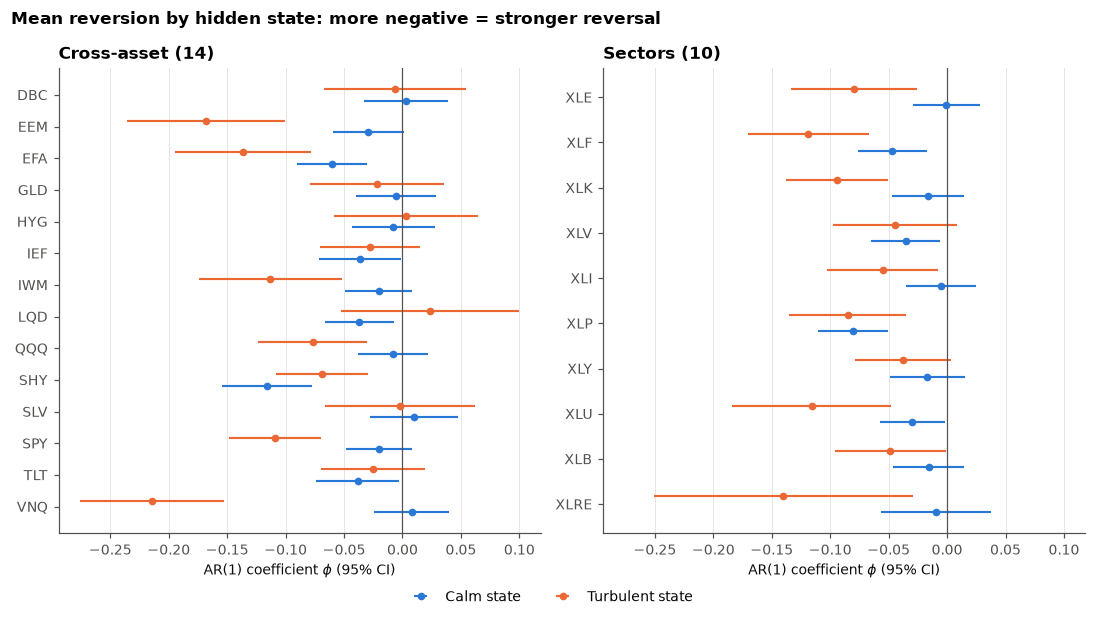

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.4), sharex=True)
for ax, (uni, grp) in zip(axes, ms.groupby("universe", sort=False)):
    dot_whisker(ax, grp, ["phi_calm", "phi_turb"], ["Calm state", "Turbulent state"], [C_CALM, C_TURB], uni)
    ax.set_xlabel(r"AR(1) coefficient $\phi$ (95% CI)")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncols=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Mean reversion by hidden state: more negative = stronger reversal", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(OUT_DIR / "fig1_phi_by_state.png", bbox_inches="tight")
plt.show()

## 6. Where does the strategy trade?

This section connects the hidden states to our strategy. For each ETF we average the turbulent-state probability over:
* uptrend vs downtrend days (the 252-day filter), and
* the strategy's **entry days** (long setup, short setup).

We also compute the **effective $\phi$ on entry days**, $\bar\phi = \overline{P(\text{calm})}\,\phi_\text{calm} + \overline{P(\text{turb})}\,\phi_\text{turb}$. This is the amount of mean reversion the model implies is available exactly when the strategy enters.

Probabilities here are *filtered* ($P(s_{t-1}\mid \text{data to } t-1)$), so they reflect only what was known on the signal day.

In [10]:
rows = {}
for t, m in ms_fits.items():
    f = frames[t]
    p_turb = m["pred"][:, 1]                       # P(s_t = turb | info at t-1)
    up = f["trend_up"].values == 1
    L = f["long_setup"].values == 1
    S = f["short_setup"].values == 1
    phi_c, phi_t = m["phi"]
    eff = lambda mask: np.nan if mask.sum() == 0 else (1 - p_turb[mask].mean()) * phi_c + p_turb[mask].mean() * phi_t
    rows[t] = {"universe": UNIVERSE[t],
               "P(turb) | trend up": p_turb[up].mean(), "P(turb) | trend down": p_turb[~up].mean(),
               "P(turb) | long setup": p_turb[L].mean() if L.any() else np.nan,
               "P(turb) | short setup": p_turb[S].mean() if S.any() else np.nan,
               "n long setups": int(L.sum()), "n short setups": int(S.sum()),
               "phi_eff long setup": eff(L), "phi_eff short setup": eff(S),
               "phi_calm": phi_c, "phi_turb": phi_t}
where = pd.DataFrame(rows).T
where = where.astype({c: float for c in where.columns if c != "universe"})
where.to_csv(OUT_DIR / "ms_state_vs_strategy.csv")
print(f"P(turb) higher in downtrends than uptrends: "
      f"{(where['P(turb) | trend down'] > where['P(turb) | trend up']).sum()} of {len(where)}")
where

P(turb) higher in downtrends than uptrends: 22 of 24


,universe,P(turb) | trend up,P(turb) | trend down,P(turb) | long setup,P(turb) | short setup,n long setups,n short setups,phi_eff long setup,phi_eff short setup,phi_calm,phi_turb
DBC,Cross-asset (14),0.2177,0.2560,0.3671,0.3591,70.0000,66.0000,-0.0003,-0.0002,0.0031,-0.0060
EEM,Cross-asset (14),0.1002,0.2499,0.3541,0.3151,97.0000,45.0000,-0.0784,-0.0730,-0.0292,-0.1681
EFA,Cross-asset (14),0.0913,0.4198,0.3034,0.5782,151.0000,36.0000,-0.0834,-0.1044,-0.0603,-0.1367
GLD,Cross-asset (14),0.2583,0.2115,0.4460,0.2818,89.0000,49.0000,-0.0126,-0.0099,-0.0053,-0.0216
HYG,Cross-asset (14),0.1349,0.5721,0.2406,0.8762,132.0000,22.0000,-0.0053,0.0017,-0.0079,0.0031
IEF,Cross-asset (14),0.3459,0.4446,0.3983,0.3412,121.0000,44.0000,-0.0329,-0.0334,-0.0365,-0.0275
IWM,Cross-asset (14),0.0696,0.3924,0.1725,0.3550,145.0000,41.0000,-0.0364,-0.0533,-0.0205,-0.1130
LQD,Cross-asset (14),0.0715,0.2358,0.2435,0.3793,141.0000,44.0000,-0.0221,-0.0139,-0.0368,0.0235
QQQ,Cross-asset (14),0.1326,0.7025,0.3399,0.7796,159.0000,39.0000,-0.0315,-0.0618,-0.0082,-0.0769
SHY,Cross-asset (14),0.4263,0.4694,0.5072,0.5963,132.0000,17.0000,-0.0920,-0.0878,-0.1159,-0.0688


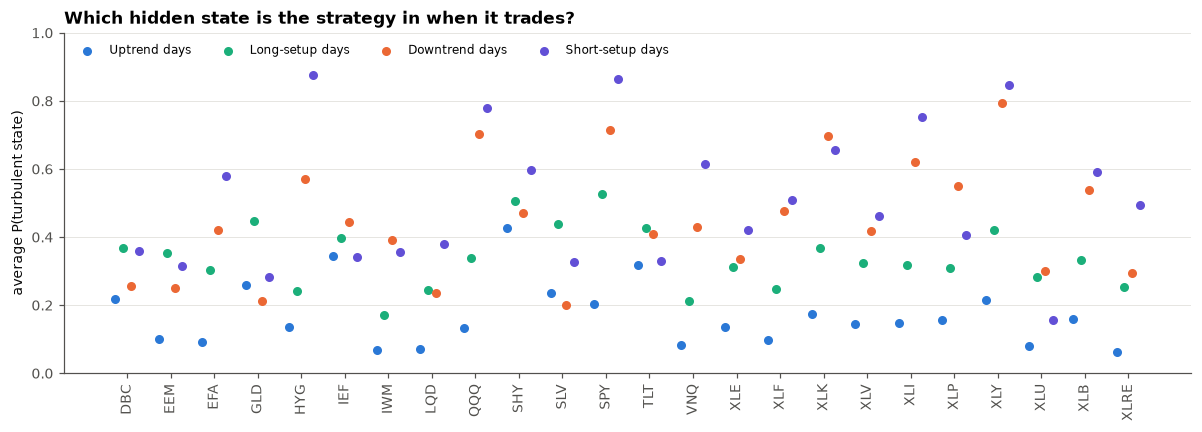

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.0))
ypos = np.arange(len(where))
cols = [("P(turb) | trend up", C_CALM, "Uptrend days"),
        ("P(turb) | long setup", "#1baf7a", "Long-setup days"),
        ("P(turb) | trend down", C_TURB, "Downtrend days"),
        ("P(turb) | short setup", "#6250d6", "Short-setup days")]
for (c, col, lab), o in zip(cols, np.linspace(-0.27, 0.27, len(cols))):
    ax.scatter(ypos + o, where[c], s=24, color=col, label=lab, zorder=3)
ax.set_xticks(ypos, where.index, rotation=90)
ax.set_ylim(0, 1)
ax.set_ylabel("average P(turbulent state)")
ax.set_title("Which hidden state is the strategy in when it trades?", loc="left")
ax.legend(ncols=4, loc="upper left", fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig2_state_vs_strategy.png", bbox_inches="tight")
plt.show()

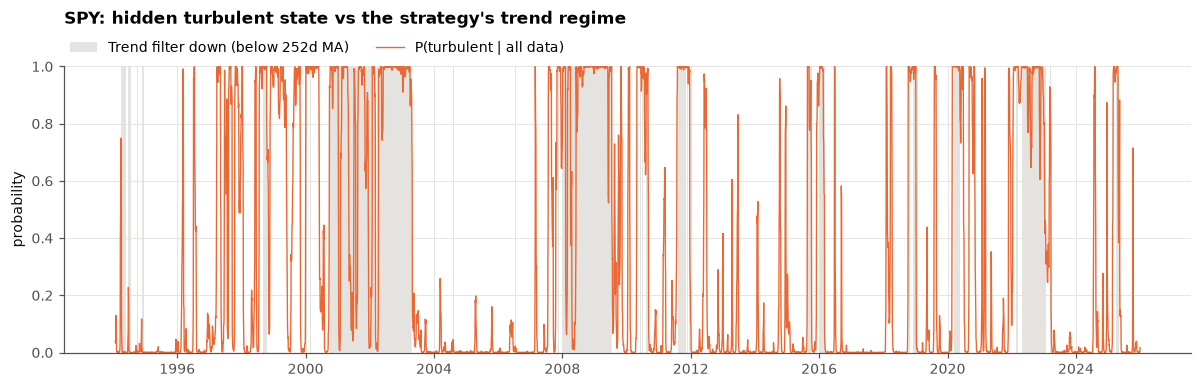

In [12]:
t = "SPY"
f, m = frames[t], ms_fits[t]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.fill_between(f.index, 0, 1, where=f["trend_up"].values == 0, step="pre", color=C_GRID, lw=0,
                label="Trend filter down (below 252d MA)")
ax.plot(f.index, m["smooth"][:, 1], color=C_TURB, lw=0.9, label="P(turbulent | all data)")
ax.set_ylim(0, 1); ax.set_ylabel("probability")
ax.xaxis.set_major_locator(mdates.YearLocator(4))
ax.set_title(f"{t}: hidden turbulent state vs the strategy's trend regime", loc="left", pad=28)
ax.legend(loc="lower left", ncols=2, bbox_to_anchor=(0, 1.02), borderaxespad=0)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig3_spy_state_prob.png", bbox_inches="tight")
plt.show()

## 7. Cross-check against statsmodels (optional)

`statsmodels.tsa.MarkovRegression` with `exog = r_{t-1}` and switching variance is the same model. If it is installed, the log-likelihoods should match.

In [13]:
try:
    import statsmodels.api as sm
    t = "SPY"; f = frames[t]
    r_sm = sm.tsa.MarkovRegression(f["y"].values, k_regimes=2, exog=f["x"].values,
                                   switching_variance=True).fit(search_reps=10, disp=False)
    print(r_sm.summary())
    print(f"\nstatsmodels ll = {r_sm.llf:.2f}   this notebook ll = {ms_fits[t]['ll']:.2f}")
except ImportError:
    print("statsmodels not installed: skipping (pip install statsmodels)")

                        Markov Switching Model Results                        
Dep. Variable:                      y   No. Observations:                 8036
Model:               MarkovRegression   Log Likelihood              -11233.533
Date:                Sun, 01 Nov 2026   AIC                          22483.066
Time:                        12:46:19   BIC                          22539.000
Sample:                             0   HQIC                         22502.207
                               - 8036                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0982      0.010      9.709      0.000       0.078       0.118
x1            -0.0198      0.014     -1.373      0.1

## 8. Out of sample: is the regime an *edge*?

In-sample significance can come from overfitting. For each ETF:
1. Fit the plain AR(1) and the MS-AR on the **first 70%** of the sample.
2. Freeze the parameters. Run the Hamilton filter forward through the last 30% and forecast each day using only information up to $t-1$:
   $\hat r_t = \sum_j P(s_t=j\mid t-1)\,(\hat\mu_j + \hat\phi_j r_{t-1})$
3. Compare:
   * $R^2_{OOS}$ vs the expanding historical mean (does the model forecast at all?)
   * $R^2$ vs the plain AR(1): **does knowing the regime help?** This is the conditional-edge question.

   Both come with a one-sided **Clark-West** test, BH-adjusted across ETFs.

In [14]:
def clark_west(y, f_small, f_big):
    adj = (y - f_small) ** 2 - ((y - f_big) ** 2 - (f_small - f_big) ** 2)
    r = ols_nw(adj, np.ones((len(adj), 1)))
    return stats.norm.sf(r["t"][0])

def oos_one(f):
    n = len(f); n_tr = int(TRAIN_FRAC * n)
    tr, te = f.iloc[:n_tr], f.iloc[n_tr:]
    y_te, x_te = te["y"].values, te["x"].values
    hm = f["y"].expanding().mean().shift(1).values[n_tr:]
    b = np.linalg.lstsq(np.column_stack([np.ones(n_tr), tr["x"]]), tr["y"].values, rcond=None)[0]
    f_ar = b[0] + b[1] * x_te
    m = fit_ms_ar(tr["y"].values, tr["x"].values, se=False)
    _, _, pred, _ = hamilton_filter(f["y"].values, f["x"].values, m["mu"], m["phi"], m["sig"], m["P"])
    pr = pred[n_tr:]
    f_ms = pr[:, 0] * (m["mu"][0] + m["phi"][0] * x_te) + pr[:, 1] * (m["mu"][1] + m["phi"][1] * x_te)
    sse = lambda fc: np.sum((y_te - fc) ** 2)
    return {"test_start": te.index[0].date(),
            "R2oos AR vs HM (%)": 100 * (1 - sse(f_ar) / sse(hm)), "CW p AR vs HM": clark_west(y_te, hm, f_ar),
            "R2oos MS vs HM (%)": 100 * (1 - sse(f_ms) / sse(hm)), "CW p MS vs HM": clark_west(y_te, hm, f_ms),
            "R2 MS vs AR (%)": 100 * (1 - sse(f_ms) / sse(f_ar)), "CW p MS vs AR": clark_west(y_te, f_ar, f_ms)}

t0 = time.time()
oos = pd.DataFrame({t: oos_one(f) for t, f in frames.items()}).T
oos.insert(0, "universe", pd.Series(UNIVERSE))
num = [c for c in oos.columns if c not in ("universe", "test_start")]
oos[num] = oos[num].astype(float)
for c in [c for c in num if c.startswith("CW p")]:
    oos[c + " BH"] = bh_adjust(oos[c])
oos.to_csv(OUT_DIR / "ms_ar_oos.csv")
print(f"OOS done in {time.time() - t0:.1f}s")
oos

OOS done in 157.9s


,universe,test_start,R2oos AR vs HM (%),CW p AR vs HM,R2oos MS vs HM (%),CW p MS vs HM,R2 MS vs AR (%),CW p MS vs AR,CW p AR vs HM BH,CW p MS vs HM BH,CW p MS vs AR BH
DBC,Cross-asset (14),2020-04-28,-0.3805,0.9738,-0.5016,0.9090,-0.1206,0.5688,0.9738,0.9914,0.8398
EEM,Cross-asset (14),2019-06-25,2.1906,0.0555,3.0872,0.0953,0.9167,0.0857,0.2439,0.3794,0.5141
EFA,Cross-asset (14),2018-12-26,1.1336,0.0836,1.1085,0.1356,-0.0254,0.2817,0.2439,0.3794,0.6263
GLD,Cross-asset (14),2019-12-16,-0.1199,0.6581,-0.0888,0.5428,0.0311,0.2942,0.7521,0.6857,0.6263
HYG,Cross-asset (14),2020-09-02,0.0201,0.2704,0.1499,0.1423,0.1299,0.1764,0.3818,0.3794,0.6049
IEF,Cross-asset (14),2019-04-08,-0.1539,0.4263,-0.1705,0.4638,-0.0166,0.6568,0.5115,0.6184,0.8398
IWM,Cross-asset (14),2018-08-14,0.4649,0.1074,0.2296,0.1750,-0.2364,0.3401,0.2439,0.3949,0.6263
LQD,Cross-asset (14),2019-04-08,-2.7195,0.8888,-3.4584,0.8861,-0.7193,0.6961,0.9367,0.9914,0.8398
QQQ,Cross-asset (14),2018-04-03,0.6067,0.0389,0.5722,0.0556,-0.0346,0.1211,0.2439,0.3794,0.5814
SHY,Cross-asset (14),2019-04-08,-0.4259,0.2310,-0.5582,0.1974,-0.1317,0.3528,0.3466,0.3949,0.6263


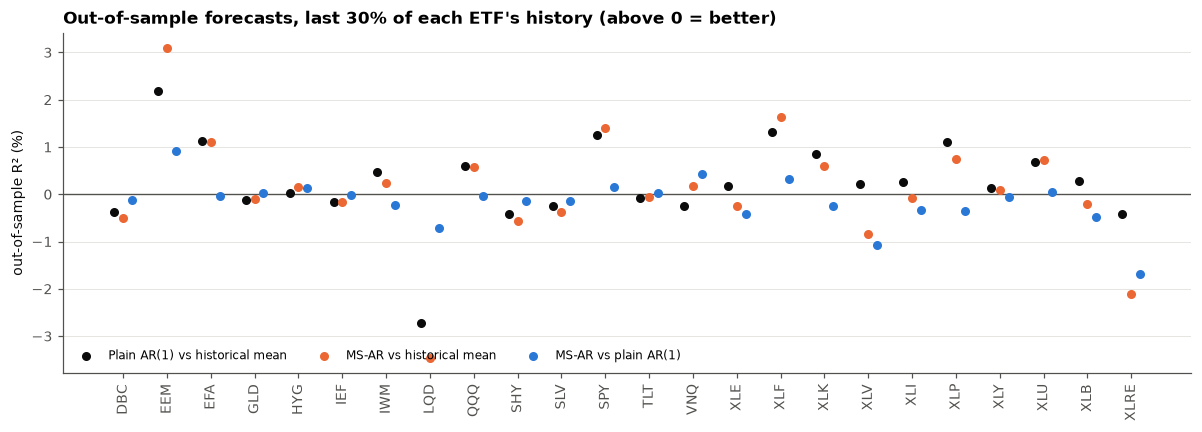

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.0))
ypos = np.arange(len(oos))
for c, col, lab, o in [("R2oos AR vs HM (%)", C_INK, "Plain AR(1) vs historical mean", -0.2),
                       ("R2oos MS vs HM (%)", C_TURB, "MS-AR vs historical mean", 0.0),
                       ("R2 MS vs AR (%)", C_CALM, "MS-AR vs plain AR(1)", 0.2)]:
    ax.scatter(ypos + o, oos[c], s=24, color=col, label=lab, zorder=3)
ax.axhline(0, color=C_MUTED, lw=0.9)
ax.set_xticks(ypos, oos.index, rotation=90)
ax.set_ylabel("out-of-sample R² (%)")
ax.set_title("Out-of-sample forecasts, last 30% of each ETF's history (above 0 = better)", loc="left")
ax.legend(ncols=3, loc="lower left", fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig4_oos.png", bbox_inches="tight")
plt.show()

## 9. Summary

In [16]:
n = len(ms)
summary = pd.Series({
    "ETFs": n,
    "Single AR(1): phi significant (BH 5%)": int((lin_ar.p_phi_BH < ALPHA).sum()),
    "MS: phi_turb < phi_calm": int((ms.phi_turb < ms.phi_calm).sum()),
    "MS: phi_calm = phi_turb rejected (raw 5%)": int((ms.p_phi_eq < ALPHA).sum()),
    "MS: phi_calm = phi_turb rejected (BH 5%)": int((ms.p_phi_eq_BH < ALPHA).sum()),
    "MS: P(turb) higher in downtrends": int((where["P(turb) | trend down"] > where["P(turb) | trend up"]).sum()),
    "OOS: MS beats historical mean (R2>0)": int((oos["R2oos MS vs HM (%)"] > 0).sum()),
    "OOS: MS beats plain AR (R2>0)": int((oos["R2 MS vs AR (%)"] > 0).sum()),
    "OOS: MS beats plain AR, CW significant (BH 5%)":
        int(((oos["R2 MS vs AR (%)"] > 0) & (oos["CW p MS vs AR BH"] < ALPHA)).sum()),
}, name="count")
summary.to_csv(OUT_DIR / "ms_ar_summary.csv")
summary.to_frame()

,count
ETFs,24
Single AR(1): phi significant (BH 5%),12
MS: phi_turb < phi_calm,19
MS: phi_calm = phi_turb rejected (raw 5%),11
MS: phi_calm = phi_turb rejected (BH 5%),5
MS: P(turb) higher in downtrends,22
OOS: MS beats historical mean (R2>0),12
OOS: MS beats plain AR (R2>0),8
"OOS: MS beats plain AR, CW significant (BH 5%)",0


### How to read the summary

1. **Regimes exist.** The turbulent state is about 2-3 times as volatile, comes in spells of weeks, and is far more likely when the price is below its 252-day MA.
2. **Mean reversion lives mainly in the turbulent state.** In most equity-type ETFs $\phi_\text{turb}$ is clearly negative while $\phi_\text{calm}$ is close to zero. Bond ETFs are the exception.
3. **The trend filter steers the strategy away from the regime where reversal is strongest.** Long entries (uptrend and below the lower band) happen mostly in the calm state. A dip raises the turbulent probability somewhat, but in our run it was still only about one in three on long-setup days. So the effective $\phi$ on those days sits between $\phi_\text{calm}$ and $\phi_\text{turb}$, and is no stronger than the single unconditional AR(1). Short setups (downtrend) see more of the turbulent state.
4. **Out of sample, knowing the regime does not improve on a plain AR(1)** in a statistically significant way. That is the same conclusion as the meta-labeling: no exploitable conditional edge.

**Caveats.** (i) The Wald test assumes two regimes exist; testing 1 vs 2 regimes is non-standard, but the variance switch is so large that this is not in doubt. (ii) Daily AR(1) measures one-day reversal, while the strategy holds for several days; set `FREQ = "W"` for a weekly robustness run. (iii) EM can stop at a local optimum; raise `MS_STARTS` to check. (iv) A $\phi$ difference of a few hundredths on daily returns is small next to a 0.1% round-trip cost.